# Task 6: Competitor Comparison

Run `python src/compare.py` first. It reads only the Task 4 and Task 5 tables in `data/processed/` and applies one framework identically to OpenAI (main), Anthropic, Databricks and NVIDIA. Population: roles open now. Hiring velocity uses the snapshot flows as the primary signal; NVIDIA's flows are provisional (one 12-day interval, because its later snapshots were stopped by HTTP 429).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
P = "../data/processed/"
card = pd.read_csv(P + "comparison_scorecard.csv").set_index("company_name")
cats = pd.read_csv(P + "comparison_categories.csv")
skills = pd.read_csv(P + "comparison_skills.csv")
dist = pd.read_csv(P + "distinctive_skills.csv")
roles = pd.read_csv(P + "comparison_roles.csv")
tech = pd.read_csv(P + "comparison_tech_stack.csv")
vel = pd.read_csv(P + "comparison_velocity.csv").set_index("company_name")
sim = pd.read_csv(P + "comparison_similarity.csv")
gaps = pd.read_csv(P + "strategic_gaps.csv")

ORDER = ["OpenAI", "Anthropic", "Databricks", "NVIDIA"]
COLOR = {"OpenAI": "#1c5cab", "Anthropic": "#d9772b", "Databricks": "#b5342c", "NVIDIA": "#3f8f2f"}
GREY = "#8b949e"
BLUE = LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#b5342c", "#f4f4f4", "#1c5cab"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

def heat(ax, grid, cmap, vmin, vmax, fmt, dark=0.5):
    ax.imshow(grid.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            if np.isnan(v): ax.text(j, i, "n/a", ha="center", va="center", fontsize=8, color=GREY); continue
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=8,
                    color="white" if (v - vmin) / (vmax - vmin) > dark else "#1f2328")
    ax.set_xticks(range(grid.shape[1]), grid.columns); ax.xaxis.tick_top()
    ax.set_yticks(range(grid.shape[0]), grid.index); ax.tick_params(length=0)
    [s.set_visible(False) for s in ax.spines.values()]

card[["open_roles", "top_skills", "top_role_category", "open_stock_change_pct", "hiring_velocity_bucket"]]

,open_roles,top_skills,top_role_category,open_stock_change_pct,hiring_velocity_bucket
company_name,,,,,
OpenAI,852,Go-to-market 30%; Python 26%; AI agents 17%; O...,Software Engineering,4.3,high
Anthropic,625,LLMs 37%; Python 29%; Go-to-market 26%; AI age...,Sales & Partnerships,-6.8,medium
Databricks,892,AWS 44%; Azure 42%; Python 40%; GCP 38%; Spark...,Solutions & Field,-3.5,medium
NVIDIA,2690,GPU 58%; Python 43%; C++ 29%; Deep learning 26...,Software Engineering,-2.4,low


## 1. Skill categories

Share of open roles that ask for at least one skill in each category (same taxonomy for all four).

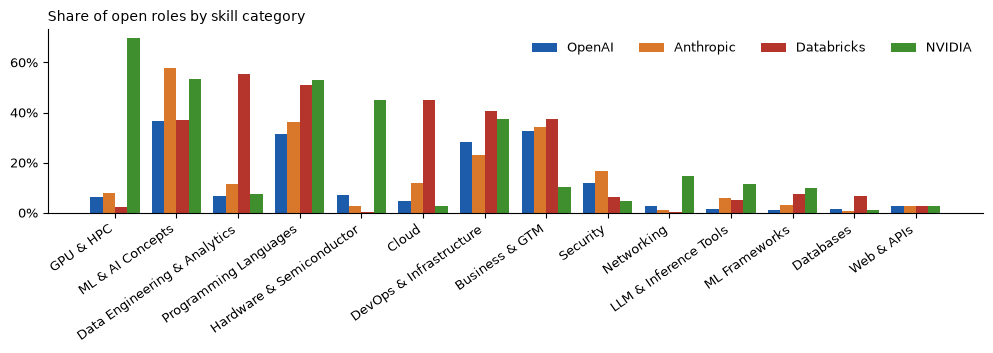

In [2]:
g = cats.pivot(index="category", columns="company_name", values="share")[ORDER]
g = g.loc[g.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(len(g)); w = .2
for k, c in enumerate(ORDER):
    ax.bar(x + (k - 1.5) * w, g[c], w, color=COLOR[c], label=c)
ax.set_xticks(x, g.index, rotation=35, ha="right"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, ncol=4); ax.set_title("Share of open roles by skill category", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Reading it:** each company has a clear lane. NVIDIA owns GPU & HPC (70% of roles) and Hardware (45%). Databricks owns Cloud (45%) and Data Engineering (55%). OpenAI and Anthropic share a profile: ML & AI concepts, Business & GTM and Security. Anthropic is higher on ML & AI concepts (58% against OpenAI's 37%). Programming Languages and DevOps are broad needs at every company.

## 2. Skill category x company heatmap

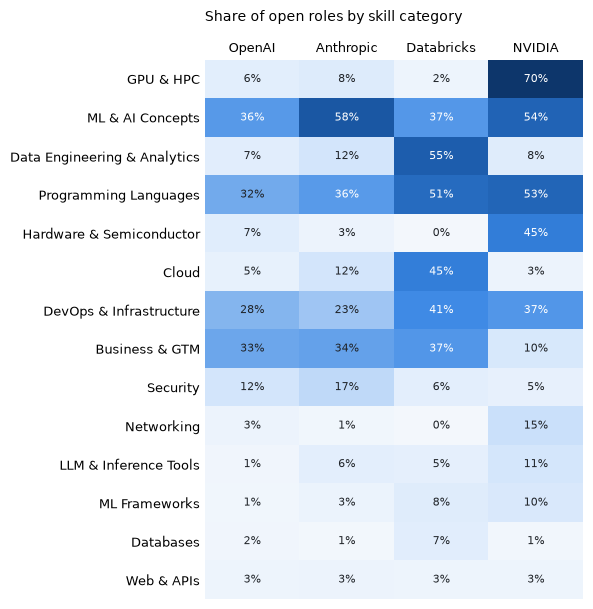

,pair,cosine
0,OpenAI / Anthropic,0.846
1,Anthropic / Databricks,0.601
2,OpenAI / Databricks,0.556
3,OpenAI / NVIDIA,0.537
4,Anthropic / NVIDIA,0.515
5,Databricks / NVIDIA,0.332


In [3]:
fig, ax = plt.subplots(figsize=(6, 0.34 * len(g) + 1.4))
heat(ax, g, BLUE, 0, 0.7, lambda v: f"{v:.0%}")
ax.set_title("Share of open roles by skill category", loc="left", fontsize=10, pad=28)
plt.tight_layout(); plt.show()
s = sim[sim.view == "skills"].pivot(index="company_a", columns="company_b", values="cosine")
pairs = sim[sim.view == "skills"].sort_values("cosine", ascending=False)
pairs.assign(pair=pairs.company_a + " / " + pairs.company_b)[["pair", "cosine"]].reset_index(drop=True)

**Reading it:** the cosine table is the same picture as one number per pair, on the 158 individual skills. OpenAI is closest to Anthropic (0.85) and about equally far from Databricks (0.56) and NVIDIA (0.54). Databricks and NVIDIA are the furthest apart (0.33).

## 3. Common and distinctive skills

Common: at least 5% of open roles at every company. Distinctive: at least 5% at one company and at least twice the mean of the other three.

Common to all four: LLMs, Python, AI agents, Machine learning, Distributed systems, Observability


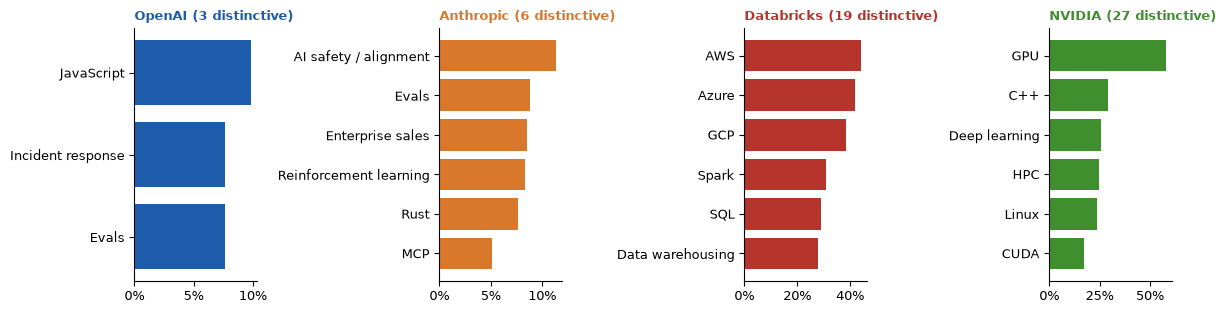

,skill,share,others_mean_share,ratio_to_others
52,JavaScript,0.0986,0.0389,2.5
53,Evals,0.0763,0.0359,2.1
54,Incident response,0.0763,0.0355,2.1


In [4]:
print("Common to all four:", ", ".join(skills[skills.scope == "common"].skill.unique()))
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, c in zip(axes, ORDER):
    d = dist[dist.company_name == c].sort_values("share").tail(6)
    ax.barh(d.skill, d.share, color=COLOR[c])
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(f"{c} ({(dist.company_name == c).sum()} distinctive)", loc="left", fontsize=9, color=COLOR[c], fontweight="bold")
plt.tight_layout(); plt.show()
dist[dist.company_name == "OpenAI"][["skill", "share", "others_mean_share", "ratio_to_others"]]

**Reading it:** only six skills are common to all four: Python, machine learning, LLMs, AI agents, observability and distributed systems. NVIDIA (27 distinctive skills) and Databricks (19) are the most specialised; OpenAI has the fewest (3), which means its skill demand is mostly shared with someone else. Anthropic's distinctive skills are AI safety, reinforcement learning, evals and MCP, a research and safety lane. Evals is distinctive for both OpenAI and Anthropic (8% and 9% of roles, against a low share at Databricks and NVIDIA).

## 4. Role categories

Share of open roles by role category, with each company's 8-week adjusted growth (Task 5) as the cell colour.

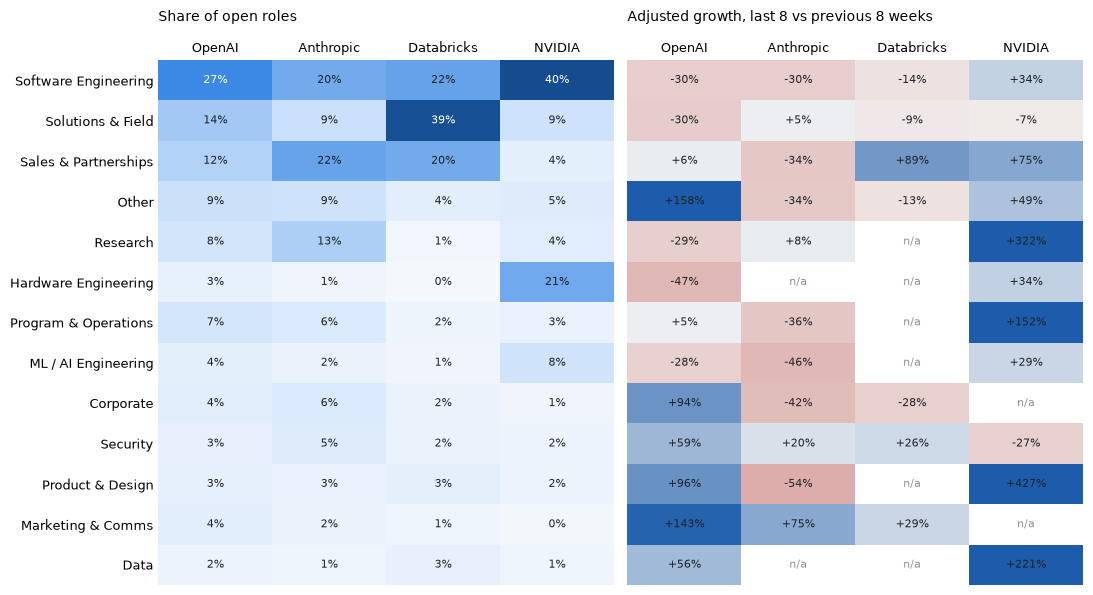

,top_role_category,top_role_category_share,top3_role_share,role_mix_hhi
company_name,,,,
OpenAI,Software Engineering,0.2664,0.5317,0.134
Anthropic,Sales & Partnerships,0.2160,0.5488,0.133
Databricks,Solutions & Field,0.3901,0.8083,0.245
NVIDIA,Software Engineering,0.3967,0.6914,0.223


In [5]:
mix = roles.pivot(index="role_category", columns="company_name", values="share")[ORDER]
mix = mix.loc[mix.mean(axis=1).sort_values(ascending=False).index]
gr = roles.pivot(index="role_category", columns="company_name", values="growth_pct_adjusted")[ORDER].reindex(mix.index)
ok = roles.pivot(index="role_category", columns="company_name", values="growth_bucket")[ORDER].reindex(mix.index) != "insufficient data"
fig, axes = plt.subplots(1, 2, figsize=(11, 0.34 * len(mix) + 1.6))
heat(axes[0], mix, BLUE, 0, 0.45, lambda v: f"{v:.0%}")
axes[0].set_title("Share of open roles", loc="left", fontsize=10, pad=28)
heat(axes[1], gr.where(ok), DIV, -150, 150, lambda v: f"{v:+.0f}%", dark=2)
axes[1].set_title("Adjusted growth, last 8 vs previous 8 weeks", loc="left", fontsize=10, pad=28)
axes[1].set_yticks([])
plt.tight_layout(); plt.show()
card[["top_role_category", "top_role_category_share", "top3_role_share", "role_mix_hhi"]]

**Reading it:** OpenAI and Anthropic have the most balanced hiring mix (concentration index 0.13 each). Databricks is concentrated: Solutions & Field is 39% of its roles and its top three categories are 81%. NVIDIA is 40% Software Engineering and 21% Hardware. OpenAI's growth is in the non-engineering functions (Marketing, Corporate, Product & Design, Security, Data); its engineering, research and solutions categories show negative adjusted growth. Small cells swing widely, so read sign and rank only.

## 5. Hiring velocity (snapshot flows first)

The unbiased view: open-stock change and opened vs closed per week between real snapshot dates. The posting-date growth is second, because it relies on the survivorship correction.

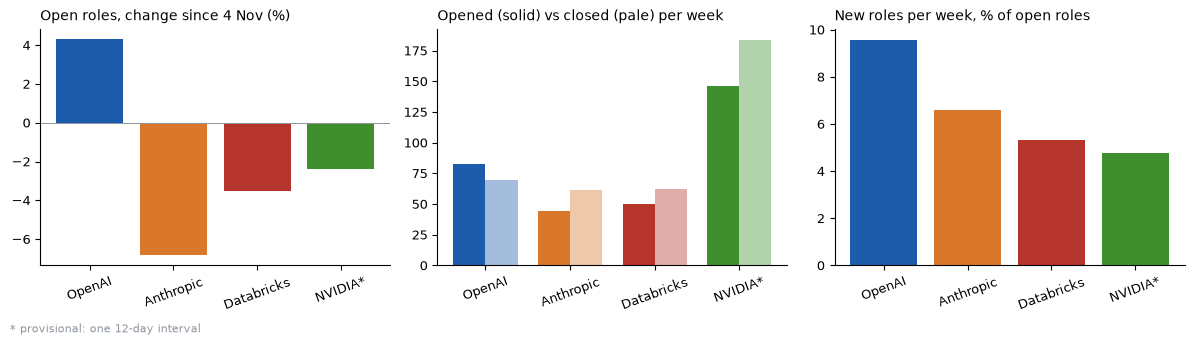

,open_stock_change_pct,opened_per_week,closed_per_week,weekly_churn_pct_of_open,new_role_rate_pct_of_open,hiring_velocity_bucket,growth_pct_adjusted,growth_confidence
company_name,,,,,,,,
OpenAI,4.3,82.5,69.6,8.5,9.57,high,32.6,normal
Anthropic,-6.8,44.6,61.5,9.0,6.61,medium,-34.5,"low (high churn, large survival correction)"
Databricks,-3.5,50.1,61.9,6.7,5.32,medium,-2.7,normal
NVIDIA,-2.4,145.8,183.8,6.7,4.76,low,36.8,normal


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
x = np.arange(4); w = .38
ch = vel.loc[ORDER, "open_stock_change_pct"]
axes[0].bar(x, ch, color=[COLOR[c] for c in ORDER]); axes[0].axhline(0, color=GREY, lw=.7)
axes[0].set_xticks(x, ORDER, rotation=20); axes[0].set_title("Open roles, change since 4 Nov (%)", loc="left", fontsize=10)
axes[1].bar(x - w/2, vel.loc[ORDER, "opened_per_week"], w, color=[COLOR[c] for c in ORDER], label="opened")
axes[1].bar(x + w/2, vel.loc[ORDER, "closed_per_week"], w, color=[COLOR[c] for c in ORDER], alpha=.4, label="closed")
axes[1].set_xticks(x, ORDER, rotation=20); axes[1].set_title("Opened (solid) vs closed (pale) per week", loc="left", fontsize=10)
axes[2].bar(x, vel.loc[ORDER, "new_role_rate_pct_of_open"], color=[COLOR[c] for c in ORDER])
axes[2].set_xticks(x, ORDER, rotation=20); axes[2].set_title("New roles per week, % of open roles", loc="left", fontsize=10)
for ax in axes:
    for lab, c in zip(ax.get_xticklabels(), ORDER):
        if c == "NVIDIA": lab.set_text("NVIDIA*"); 
axes[0].set_xticks(x, ["OpenAI", "Anthropic", "Databricks", "NVIDIA*"], rotation=20)
axes[1].set_xticks(x, ["OpenAI", "Anthropic", "Databricks", "NVIDIA*"], rotation=20)
axes[2].set_xticks(x, ["OpenAI", "Anthropic", "Databricks", "NVIDIA*"], rotation=20)
fig.text(0.01, -0.02, "* provisional: one 12-day interval", fontsize=8, color=GREY)
plt.tight_layout(); plt.show()
vel.loc[ORDER, ["open_stock_change_pct", "opened_per_week", "closed_per_week", "weekly_churn_pct_of_open",
                "new_role_rate_pct_of_open", "hiring_velocity_bucket", "growth_pct_adjusted", "growth_confidence"]]

**Reading it:** OpenAI is the only company whose open stock grew, and it has the highest new-role rate. Anthropic, Databricks and NVIDIA closed more than they opened over the window. Anthropic's adjusted posting-date growth is marked low confidence because about 9 to 10% of its open roles close each week, so the survival correction is large. NVIDIA's flows rest on one interval.

## 6. Tech-stack patterns

From `tech_stack_tags` (skills without the concept and business categories). Cloud mix is the share of cloud-tagged roles that name each provider.

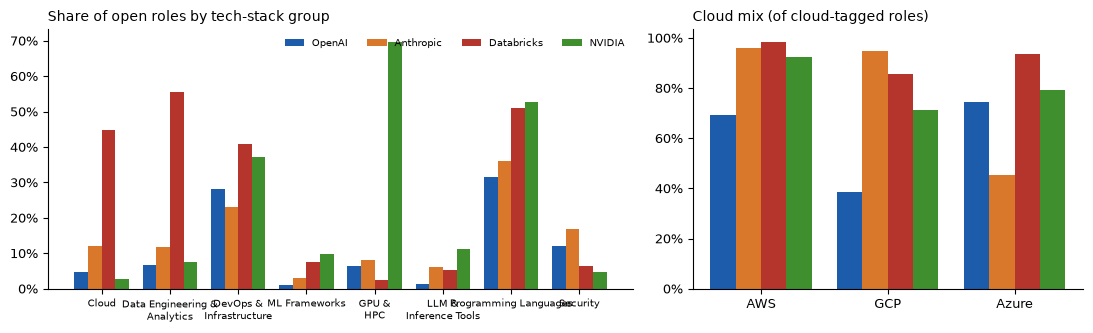

Roles naming the most-mentioned cloud provider: {'OpenAI': 29, 'Anthropic': 72, 'Databricks': 394, 'NVIDIA': 71}


company_name,OpenAI,Anthropic,Databricks,NVIDIA
name,,,,
Cloud,Azure; AWS; GCP,AWS; GCP; Azure,AWS; Azure; GCP,AWS; Azure; GCP
GPU & HPC,GPU; HPC; Compilers,GPU; HPC; Compilers,GPU; HPC; CUDA,GPU; HPC; CUDA
LLM & Inference Tools,MCP; vLLM; SGLang,MCP; Vector databases; Triton,Vector databases; LangChain; MCP,TensorRT; vLLM; NeMo
ML Frameworks,PyTorch; TensorFlow; JAX,PyTorch; JAX; pandas,MLflow; PyTorch; scikit-learn,PyTorch; TensorFlow; JAX


In [7]:
t = tech[tech.kind == "category"].pivot(index="name", columns="company_name", values="share_of_open")[ORDER]
keep = ["Cloud", "Data Engineering & Analytics", "DevOps & Infrastructure", "ML Frameworks", "GPU & HPC",
        "LLM & Inference Tools", "Programming Languages", "Security"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.5, 1]})
tt = t.loc[keep]; x = np.arange(len(tt)); w = .2
for k, c in enumerate(ORDER):
    axes[0].bar(x + (k - 1.5) * w, tt[c], w, color=COLOR[c], label=c)
axes[0].set_xticks(x, [k.replace(" & ", " &\n") for k in tt.index], fontsize=7); axes[0].legend(frameon=False, ncol=4, fontsize=7)
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); axes[0].set_title("Share of open roles by tech-stack group", loc="left", fontsize=10)
cl = tech[tech.kind == "cloud_provider"].pivot(index="name", columns="company_name", values="share_of_cloud_roles")[ORDER].loc[["AWS", "GCP", "Azure"]]
x = np.arange(3)
for k, c in enumerate(ORDER):
    axes[1].bar(x + (k - 1.5) * w, cl[c], w, color=COLOR[c])
axes[1].set_xticks(x, cl.index); axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[1].set_title("Cloud mix (of cloud-tagged roles)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
n_cloud = tech[(tech.kind == "cloud_provider")].groupby("company_name").postings.max()
print("Roles naming the most-mentioned cloud provider:", n_cloud.reindex(ORDER).to_dict())
tech[(tech.kind == "category") & (tech.name.isin(["Cloud", "GPU & HPC", "ML Frameworks", "LLM & Inference Tools"]))].pivot(
    index="name", columns="company_name", values="top_tags")[ORDER]

**Reading it:** Databricks is multi-cloud by design (AWS, Azure and GCP each in 38-44% of its roles). Anthropic names AWS and GCP in almost all of its cloud-tagged roles, Azure in under half. OpenAI has very few cloud-tagged roles (under 5% of its postings), so its cloud mix rests on a small base. NVIDIA's stack is GPU/HPC, hardware and C++. OpenAI's infrastructure demand is in DevOps and distributed systems (28% of roles) rather than named cloud providers or ML frameworks (1%). Postings often omit framework names, so ML Frameworks is understated everywhere.

## 7. Seniority

Seniority comes from title keywords, so it is complete but coarse. "Unmarked" means no seniority word in the title. Anthropic and OpenAI rarely use "Senior", so the senior/staff/principal row is shown but not interpreted.

In [8]:
cols = ["pct_unmarked_title", "pct_manager_lead", "pct_director_exec", "pct_intern", "pct_senior_staff_principal"]
(card.loc[ORDER, cols] * 100).round(0).astype(int).astype(str).add("%").rename(columns=lambda c: c[4:].replace("_", " "))

,unmarked title,manager lead,director exec,intern,senior staff principal
company_name,,,,,
OpenAI,59%,30%,7%,0%,3%
Anthropic,49%,30%,4%,0%,17%
Databricks,33%,19%,5%,1%,41%
NVIDIA,20%,14%,2%,8%,55%


**Reading it:** the comparable markers are manager/lead (30% at OpenAI and Anthropic, 14-19% at the others), director or executive (7% at OpenAI, the highest) and interns (only NVIDIA, 8%, and Databricks, 1%). OpenAI's 59% unmarked share is the highest, which mostly reflects its title style, not a junior mix.

## 8. Strategic gaps and white space

Below peers: share at most half the mean of the other three, where those three average 10% or more. White space: skill categories where every company is at or below 10%, and areas where all four are growing.

In [9]:
below = gaps[gaps.gap_type == "below_peers"]
print("Below peers, by company and type")
display(below.groupby(["company_name", "item_type"]).item.agg(lambda s: ", ".join(s)).unstack().reindex(ORDER).fillna(""))
print("White space")
gaps[gaps.company_name == "all four"][["gap_type", "item_type", "item", "note"]]

Below peers, by company and type


item_type,role_category,skill,skill_category
company_name,,,
OpenAI,,"C++, SQL, Machine learning, Spark, ETL / ELT, ...","Cloud, Data Engineering & Analytics, GPU & HPC..."
Anthropic,Solutions & Field,"C++, Spark, Azure, GPU","GPU & HPC, Hardware & Semiconductor"
Databricks,,"LLMs, Inference, GPU","GPU & HPC, Hardware & Semiconductor"
NVIDIA,"Sales & Partnerships, Solutions & Field","SQL, Spark, ETL / ELT, Data warehousing, AWS, ...","Business & GTM, Cloud, Data Engineering & Anal..."


White space


,gap_type,item_type,item,note
12,white_space_thin,skill_category,Databases,every company at or below 10% (max 7%)
13,white_space_thin,skill_category,ML Frameworks,every company at or below 10% (max 10%)
14,white_space_thin,skill_category,Web & APIs,every company at or below 10% (max 3%)
43,white_space_all_growing,skill,Go-to-market,"recent vs older share: OpenAI x1.4, Anthropic ..."


**Reading it:** OpenAI sits well below its peers on Cloud, Data Engineering, GPU & HPC and Hardware, which are exactly the lanes where Databricks and NVIDIA specialise, so OpenAI is a model and product company rather than a platform or silicon company. It is above peers in Business & GTM (+6 points) and Security (+3). Skill categories that are thin everywhere are Databases, ML Frameworks and Web & APIs. Go-to-market is the only skill whose share is growing at all four, strongest at NVIDIA from a low base. No role category is growing at all four.